# 🐱🚗 FarmTech Solutions — Visão Computacional com YOLOv5

**FIAP · Fase 6 · PBL — Entrega 1**
**AlunoS:**
1. Victor Vergara Koshikene      — RM 568813
2. Leonardo Lima de Queiroz      — RM 573539
3. Vinicius Prado Speria         — RM 572741
4. Leonardo Ribeiro de Souza     — RM 571534
5. Matheus Costa Manzoli Machado — RM 571814

---

## Contexto

A FarmTech Solutions expandiu seus serviços de IA para além do agronegócio (saúde animal, segurança patrimonial, controle de acesso e visão computacional). Neste notebook, simulamos a visita a um cliente que quer entender, na prática, como funciona um sistema de **detecção de objetos**.

## Objetivo

Treinar um modelo **YOLOv5** customizado capaz de detectar duas classes bem diferentes entre si:

| ID | Classe | Exemplo de aplicação FarmTech |
|---|---|---|
| 0 | `gato` | monitoramento de animais em propriedades (saúde animal) |
| 1 | `carro` | segurança patrimonial e controle de acesso de veículos |

Além disso, comparamos **cenários com diferentes números de épocas** (30, 60 e 100) para avaliar o impacto desse hiperparâmetro em **acurácia, erro e desempenho**.

## Sumário

1. Configuração do ambiente
2. Construção do dataset (COCO 2017)
3. Rotulação no Make Sense AI
4. Controle de qualidade dos rótulos
5. Preparação dos dados para o YOLOv5
6. Treinamento: cenários com diferentes épocas
7. Avaliação na validação: comparação dos cenários
8. Teste: inferência em imagens nunca vistas
9. Conclusões, pontos fortes e limitações
10. Referências

> **Como executar:** `Runtime → Change runtime type → T4 GPU` e depois `Runtime → Run all`. O dataset e os rótulos ficam no Google Drive (`MyDrive/FarmTech_Fase6`).

## 1. Configuração do ambiente

Nesta etapa verificamos a GPU, conectamos o Google Drive (onde ficam imagens, rótulos e resultados) e centralizamos todas as configurações do experimento em uma única célula. Assim, para testar outro cenário basta alterar a lista `EPOCAS`.

In [ ]:
# Verifica se o ambiente possui GPU (treinar na CPU seria muito mais lento)
import torch                                              # biblioteca de deep learning usada pelo YOLOv5

print("GPU disponível:", torch.cuda.is_available())       # True quando o runtime é GPU
if torch.cuda.is_available():
    print("Placa:", torch.cuda.get_device_name(0))        # nome da GPU (esperado: Tesla T4)

GPU disponível: True
Placa: Tesla T4


In [ ]:
# Conecta o Google Drive ao Colab para ler/gravar arquivos de forma permanente
from google.colab import drive

drive.mount('/content/drive')                             # pede autorização na primeira execução

Mounted at /content/drive


In [ ]:
# ---------------- Configurações centrais do experimento ----------------
import os

BASE_DIR = "/content/drive/MyDrive/FarmTech_Fase6"   # pasta do projeto no Drive (imagens, rótulos, resultados)
DATASET_DIR = "/content/dataset"                     # dataset no formato YOLOv5 (montado no disco do Colab)
YOLO_DIR    = "/content/yolov5"                      # repositório do YOLOv5
RESULT_DIR  = os.path.join(BASE_DIR, "resultados")   # cópia permanente dos resultados no Drive

SEED    = 42                                            # semente fixa: seleção e treino reproduzíveis
CLASSES = {0: "gato", 1: "carro"}                       # ordem idêntica à usada no Make Sense

# Cenários de treino: o único hiperparâmetro que varia é o número de épocas
EPOCAS     = [30, 60, 100]
IMG_SIZE   = 640                                        # resolução de entrada da rede
BATCH      = 16                                         # imagens por lote (cabe bem na T4)
CONF_TESTE = 0.25                                       # confiança mínima para exibir uma detecção no teste

os.environ["WANDB_MODE"] = "disabled"                   # desativa o Weights & Biases (evita pedido de login)
os.makedirs(RESULT_DIR, exist_ok=True)                  # garante a pasta de resultados no Drive
print("Configuração carregada. Cenários:", EPOCAS)

Configuração carregada. Cenários: [30, 60, 100]


## 2. Construção do dataset (COCO 2017)

### Por que usar o COCO em vez de fotos próprias?

Fotos tiradas por nós dependeriam de muitas variáveis (iluminação, fundo, ângulo, câmera) e tenderiam a ficar parecidas entre si. O **COCO (Common Objects in Context)** é um dataset público com fotos reais e muito variadas, o que favorece a generalização do modelo.

### Por que o conjunto `val2017`?

Os pesos pré-treinados do YOLOv5 (`yolov5s.pt`) foram treinados no `train2017`. Usando imagens do **`val2017`**, garantimos que o modelo de partida **nunca viu estas fotos**, evitando vazamento de dados (*data leakage*) e resultados artificialmente otimistas.

### Composição do dataset

| Grupo | Treino | Validação | Teste | Total |
|---|---|---|---|---|
| Gatos (sem carro) | 32 | 4 | 4 | 40 |
| Carros (sem gato) | 32 | 4 | 4 | 40 |
| Mistas (gato + carro, extra) | 3 | 1 | 1 | 5 |
| **Total** | **67** | **9** | **9** | **85** |

As 80 imagens exigidas pelo enunciado (40 + 40, divididas em 32/4/4) são complementadas por 5 imagens **mistas** extras, que ajudam a avaliar o modelo em cenas com os dois objetos.

### Critérios de qualidade aplicados na seleção

- **Gatos:** 1 a 2 gatos por imagem, com o maior ocupando ≥ 10% da área.
- **Carros:** 1 a 3 carros por imagem, com o maior ocupando ≥ 5% da área (evita ruas lotadas de carros minúsculos).
- **Mistas:** 1 a 2 gatos e 1 a 3 carros, cada classe com ≥ 3% da área.
- Sorteio com semente fixa (`SEED = 42`) para reprodutibilidade.

> As anotações do COCO são usadas **apenas como filtro** para encontrar as imagens. Toda a rotulação usada no treino foi feita manualmente no Make Sense AI (Seção 3).

In [ ]:
# Baixa apenas o arquivo de anotações do COCO 2017 (~241 MB) e extrai o JSON do val2017 (~20 MB)
ANN_FILE = "/content/coco_annotations/instances_val2017.json"

if not os.path.exists(ANN_FILE):                                       # evita baixar de novo se já existir
    !wget -q http://images.cocodataset.org/annotations/annotations_trainval2017.zip -P /content
    !unzip -q -o -j /content/annotations_trainval2017.zip annotations/instances_val2017.json -d /content/coco_annotations

!ls -lh /content/coco_annotations                                      # confere o arquivo extraído

total 20M
-rw-rw-r-- 1 root root 20M Sep  1  2017 instances_val2017.json


In [ ]:
# Instala a API oficial do COCO, usada para consultar categorias e imagens no JSON de anotações
!pip install -q pycocotools

In [ ]:
# ---------------- Seleção e download das imagens ----------------
import random, time, csv
from urllib.parse import urlparse
import requests
from pycocotools.coco import COCO

random.seed(SEED)                                            # torna o sorteio reproduzível

# Quantidade de imagens por grupo: (treino, validação, teste)
SPLITS = {"gato": (32, 4, 4), "carro": (32, 4, 4), "mista": (3, 1, 1)}

coco   = COCO(ANN_FILE)                                      # carrega as anotações em memória
cat_id = coco.getCatIds(catNms=["cat"])[0]                   # ID da categoria "cat" no COCO
car_id = coco.getCatIds(catNms=["car"])[0]                   # ID da categoria "car" no COCO

def objetos_validos(img_id, categoria, n_min, n_max, area_min):
    # Verifica a quantidade de objetos da categoria e se o maior ocupa ao menos 'area_min' da imagem
    info = coco.loadImgs(img_id)[0]                                              # metadados da imagem
    anns = coco.loadAnns(coco.getAnnIds(imgIds=img_id, catIds=[categoria], iscrowd=False))
    if not (n_min <= len(anns) <= n_max):                                        # fora do intervalo desejado
        return False
    area_img = info["width"] * info["height"]                                    # área total em pixels
    return max(a["area"] for a in anns) / area_img >= area_min                   # fração ocupada pelo maior objeto

# Conjuntos de imagens por categoria
ids_gato, ids_carro = set(coco.getImgIds(catIds=[cat_id])), set(coco.getImgIds(catIds=[car_id]))

cand = {
    "gato":  [i for i in sorted(ids_gato - ids_carro) if objetos_validos(i, cat_id, 1, 2, 0.10)],
    "carro": [i for i in sorted(ids_carro - ids_gato) if objetos_validos(i, car_id, 1, 3, 0.05)],
    "mista": [i for i in sorted(ids_gato & ids_carro) if objetos_validos(i, cat_id, 1, 2, 0.03)
                                                      and objetos_validos(i, car_id, 1, 3, 0.03)],
}

print("Candidatos após filtros de qualidade:")
for g, ids in cand.items():
    print(f"  {g}: {len(ids)} disponíveis (precisa de {sum(SPLITS[g])})")
    assert len(ids) >= sum(SPLITS[g]), f"Poucos candidatos para '{g}'. Relaxe os filtros."

# Sorteia e distribui cada grupo entre treino, validação e teste
selecao = []
for g, (n_tr, n_va, n_te) in SPLITS.items():
    escolhidas = random.sample(cand[g], n_tr + n_va + n_te)
    selecao += [(g, "treino", i) for i in escolhidas[:n_tr]]
    selecao += [(g, "validacao", i) for i in escolhidas[n_tr:n_tr + n_va]]
    selecao += [(g, "teste", i) for i in escolhidas[n_tr + n_va:]]

def baixar(url, destino, tentativas=3):
    # Baixa uma imagem apenas do domínio oficial do COCO, com timeout e novas tentativas
    if urlparse(url).hostname != "images.cocodataset.org":                   # aceita só o host esperado
        return False
    for _ in range(tentativas):
        try:
            r = requests.get(url, timeout=30)
            r.raise_for_status()                                             # erro HTTP vira exceção
            with open(destino, "wb") as f:
                f.write(r.content)
            return True
        except requests.RequestException:
            time.sleep(2)                                                    # espera antes de tentar de novo
    return False

manifesto, falhas = [], []
for grupo, divisao, img_id in selecao:
    info    = coco.loadImgs(img_id)[0]
    pasta   = os.path.join(BASE_DIR, divisao)
    os.makedirs(pasta, exist_ok=True)
    destino = os.path.join(pasta, info["file_name"])
    if not os.path.exists(destino) and not baixar(info["coco_url"], destino):  # só baixa o que falta
        falhas.append(info["file_name"])
        continue
    manifesto.append([info["file_name"], grupo, divisao, info["coco_url"], info["flickr_url"]])

# Manifesto: registra origem, grupo e divisão de cada imagem (rastreabilidade e citação de fontes)
with open(os.path.join(BASE_DIR, "manifesto_dataset.csv"), "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["arquivo", "grupo", "divisao", "coco_url", "flickr_url"])
    w.writerows(manifesto)

print(f"\nImagens no dataset: {len(manifesto)} | Falhas: {falhas}")

loading annotations into memory...
Done (t=1.10s)
creating index...
index created!
Candidatos após filtros de qualidade:
  gato: 110 disponíveis (precisa de 40)
  carro: 66 disponíveis (precisa de 40)
  mista: 6 disponíveis (precisa de 5)

Imagens no dataset: 85 | Falhas: []


In [ ]:
# Confere a quantidade de imagens em cada pasta do Drive (esperado: 67 / 9 / 9)
import glob

for divisao in ["treino", "validacao", "teste"]:
    n = len(glob.glob(os.path.join(BASE_DIR, divisao, "*.jpg")))   # conta só as imagens .jpg
    print(f"{divisao:10s} -> {n} imagens")

treino     -> 67 imagens
validacao  -> 9 imagens
teste      -> 9 imagens


## 3. Rotulação no Make Sense AI

A rotulação foi feita manualmente em [makesense.ai](https://www.makesense.ai), seguindo o passo a passo:

1. Upload das imagens da pasta `treino` e escolha de **Object Detection**.
2. Criação das classes **na ordem fixa**: `gato` (ID 0) e `carro` (ID 1).
3. Desenho de uma caixa (*bounding box*) justa em volta de **cada** gato e carro visível, inclusive nas imagens mistas.
4. Exportação em **YOLO format** (`Actions → Export Annotations`).
5. Repetição do processo para a pasta `validacao`, com as mesmas classes na mesma ordem.

Os rótulos foram salvos no Drive em `treino/labels_treino/` e `validacao/labels_validacao/`.

### Formato YOLO

Cada imagem tem um `.txt` com o mesmo nome, e cada linha descreve um objeto:

```
<classe> <x_centro> <y_centro> <largura> <altura>
```

As coordenadas são **normalizadas entre 0 e 1** em relação ao tamanho da imagem.

### Por que a validação também foi rotulada?

O enunciado pede a rotulação do treino, mas o YOLOv5 precisa dos rótulos da **validação** para calcular precisão, recall e mAP a cada época. Sem eles, não seria possível comparar os cenários de épocas. As imagens de **teste** não foram rotuladas: elas são usadas para inferência e avaliação visual, simulando o uso real do modelo (ver Seção 8).

### 3.1 Obtenção dos rótulos

Os rótulos produzidos no Make Sense estão versionados no repositório do projeto (`dataset/labels/`).
Se o Drive de quem executa este notebook ainda não tiver os rótulos, a célula abaixo os copia do GitHub.
Assim, o notebook pode ser reproduzido em qualquer conta.

In [ ]:
import shutil

# ---------------- Obtém os rótulos do GitHub, se não estiverem no Drive ----------------
GITHUB_REPO = "koshivv/fiap-farmtech_solutions-fase06"     # repositório público do projeto
REPO_DIR    = "/content/repo_projeto"                      # clone local do repositório
ESPERADOS   = {"treino": 67, "validacao": 9}               # quantidade de rótulos por divisão

def rotulos_completos():
    # Retorna True se todas as divisões já têm a quantidade esperada de rótulos no Drive
    return all(
        len(glob.glob(f"{BASE_DIR}/{div}/labels_{div}/*.txt")) == n
        for div, n in ESPERADOS.items()
    )

if rotulos_completos():
    print("✅ Rótulos já presentes no Drive.")
else:
    if not os.path.exists(REPO_DIR):                       # clona só uma vez
        !git clone -q --depth 1 https://github.com/{GITHUB_REPO}.git {REPO_DIR}
    for div in ESPERADOS:                                   # copia os .txt para o Drive
        shutil.copytree(f"{REPO_DIR}/dataset/labels/{div}",
                        f"{BASE_DIR}/{div}/labels_{div}", dirs_exist_ok=True)
    print("📥 Rótulos copiados do GitHub.")

for div in ESPERADOS:                                       # confere: esperado 67 e 9
    print(div, "->", len(glob.glob(f"{BASE_DIR}/{div}/labels_{div}/*.txt")), "rótulos")

✅ Rótulos já presentes no Drive.
treino -> 67 rótulos
validacao -> 9 rótulos


## 4. Controle de qualidade dos rótulos

Erros de rotulação (classe trocada, imagem sem rótulo, coordenadas inválidas) não geram erro no treino: eles apenas pioram o modelo silenciosamente. Por isso, validamos os rótulos de duas formas:

1. **Verificação estrutural:** toda imagem tem rótulo, as classes são 0 ou 1 e as coordenadas estão entre 0 e 1.
2. **Verificação semântica:** comparamos as classes rotuladas com o grupo de origem de cada imagem registrado no manifesto (ex.: uma imagem do grupo `carro` só pode conter a classe 1).

In [ ]:
# ---------------- Verificação estrutural dos rótulos ----------------
from collections import Counter

def verificar_rotulos():
    # Confere pareamento imagem/rótulo, validade das linhas e contagem por classe
    for divisao in ["treino", "validacao"]:
        pasta_img = os.path.join(BASE_DIR, divisao)
        pasta_lbl = os.path.join(pasta_img, f"labels_{divisao}")
        nomes_img = {os.path.splitext(os.path.basename(p))[0] for p in glob.glob(f"{pasta_img}/*.jpg")}
        arqs_lbl  = glob.glob(f"{pasta_lbl}/*.txt")
        nomes_lbl = {os.path.splitext(os.path.basename(p))[0] for p in arqs_lbl}

        caixas, imgs_classe, invalidos = Counter(), Counter(), []
        for arq in arqs_lbl:
            classes_img = set()
            with open(arq) as f:
                for n, linha in enumerate(f, 1):
                    p = linha.split()
                    if not p:                                           # ignora linhas vazias
                        continue
                    try:
                        c, coords = int(p[0]), list(map(float, p[1:]))
                        ok = c in CLASSES and len(coords) == 4 and all(0 <= v <= 1 for v in coords)
                    except ValueError:
                        ok = False
                    if not ok:
                        invalidos.append((os.path.basename(arq), n, linha.strip()))
                        continue
                    caixas[CLASSES[c]] += 1                             # total de caixas por classe
                    classes_img.add(CLASSES[c])
            imgs_classe.update(classes_img)                             # imagens que contêm cada classe

        print(f"=== {divisao} ===")
        print(f"Imagens: {len(nomes_img)} | Rótulos: {len(nomes_lbl)}")
        print("Imagens sem rótulo:", sorted(nomes_img - nomes_lbl))
        print("Rótulos sem imagem:", sorted(nomes_lbl - nomes_img))
        print("Caixas por classe:", dict(caixas))
        print("Imagens contendo cada classe:", dict(imgs_classe))
        print("Linhas inválidas:", invalidos or "nenhuma", "\n")

verificar_rotulos()

=== treino ===
Imagens: 67 | Rótulos: 67
Imagens sem rótulo: []
Rótulos sem imagem: []
Caixas por classe: {'gato': 37, 'carro': 54}
Imagens contendo cada classe: {'gato': 35, 'carro': 35}
Linhas inválidas: nenhuma 

=== validacao ===
Imagens: 9 | Rótulos: 9
Imagens sem rótulo: []
Rótulos sem imagem: []
Caixas por classe: {'gato': 5, 'carro': 8}
Imagens contendo cada classe: {'gato': 5, 'carro': 5}
Linhas inválidas: nenhuma 



In [ ]:
# ---------------- Verificação semântica (rótulos x manifesto) ----------------
import pandas as pd

ESPERADO = {"gato": {0}, "carro": {1}, "mista": {0, 1}}         # classes esperadas por grupo de origem

def checar_manifesto():
    # Lista imagens cujas classes rotuladas diferem do grupo de origem
    manif = pd.read_csv(os.path.join(BASE_DIR, "manifesto_dataset.csv"))
    divergencias = []
    for _, r in manif[manif.divisao.isin(["treino", "validacao"])].iterrows():
        arq = os.path.join(BASE_DIR, r.divisao, f"labels_{r.divisao}", os.path.splitext(r.arquivo)[0] + ".txt")
        with open(arq) as f:
            encontrado = {int(l.split()[0]) for l in f if l.strip()}   # classes presentes no rótulo
        if encontrado != ESPERADO[r.grupo]:
            divergencias.append((r.divisao, r.arquivo, r.grupo, sorted(ESPERADO[r.grupo]), sorted(encontrado)))
    if divergencias:
        display(pd.DataFrame(divergencias, columns=["divisão", "arquivo", "grupo", "esperado", "rotulado"]))
    else:
        print("✅ Todos os rótulos são consistentes com o grupo de origem.")

checar_manifesto()

✅ Todos os rótulos são consistentes com o grupo de origem.


### Correção encontrada

Na primeira verificação, a imagem `treino/000000354829.jpg` (grupo `carro`, contendo apenas um carro) estava rotulada com a classe `0` (gato). O treino resultava em 36 imagens com gato e 34 com carro, em vez de 35 e 35.

A caixa estava correta; apenas a classe foi trocada. A célula abaixo aplica a correção de forma **idempotente** (só altera se ainda estiver errada), e em seguida repetimos as verificações.

> **Lição:** a verificação semântica pegou um erro humano que a verificação estrutural não detectaria, já que a classe 0 é válida.

In [ ]:
# Corrige a classe da imagem 000000354829 (carro rotulado como gato), apenas se necessário
arq = os.path.join(BASE_DIR, "treino", "labels_treino", "000000354829.txt")

with open(arq) as f:
    linhas = [l.split() for l in f if l.strip()]                 # lê as caixas da imagem

if any(p[0] == "0" for p in linhas):                             # ainda existe classe "gato"?
    with open(arq, "w") as f:
        f.writelines(" ".join(["1"] + p[1:]) + "\n" for p in linhas)   # troca a classe para "carro"
    print("Rótulo corrigido.")
else:
    print("Rótulo já estava correto.")

Rótulo já estava correto.


In [ ]:
# Repete as duas verificações após a correção
# Esperado no treino: 35 imagens com gato e 35 com carro; nenhuma divergência no manifesto
verificar_rotulos()
checar_manifesto()

=== treino ===
Imagens: 67 | Rótulos: 67
Imagens sem rótulo: []
Rótulos sem imagem: []
Caixas por classe: {'gato': 37, 'carro': 54}
Imagens contendo cada classe: {'gato': 35, 'carro': 35}
Linhas inválidas: nenhuma 

=== validacao ===
Imagens: 9 | Rótulos: 9
Imagens sem rótulo: []
Rótulos sem imagem: []
Caixas por classe: {'gato': 5, 'carro': 8}
Imagens contendo cada classe: {'gato': 5, 'carro': 5}
Linhas inválidas: nenhuma 

✅ Todos os rótulos são consistentes com o grupo de origem.


## 5. Preparação dos dados para o YOLOv5

O YOLOv5 encontra o rótulo de cada imagem trocando `/images/` por `/labels/` no caminho. Por isso, copiamos os dados do Drive para a estrutura abaixo, no disco do Colab (mais rápido que ler do Drive durante o treino):

```
/content/dataset/
├── images/  train/  val/  test/
├── labels/  train/  val/
└── farmtech.yaml
```

O arquivo `farmtech.yaml` informa ao YOLOv5 onde estão os dados e quais são as classes.

In [ ]:
# Clona o repositório oficial do YOLOv5 (se ainda não existir) e instala as dependências
if not os.path.exists(YOLO_DIR):
    !git clone -q https://github.com/ultralytics/yolov5 {YOLO_DIR}
%cd {YOLO_DIR}
!pip install -q -r requirements.txt

/content/yolov5
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 37.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 10.1 MB/s eta 0:00:00


In [ ]:
# Monta o dataset no formato esperado pelo YOLOv5

if os.path.exists(DATASET_DIR):                                  # recria do zero para evitar sobras
    shutil.rmtree(DATASET_DIR)
for sub in ["images/train", "images/val", "images/test", "labels/train", "labels/val"]:
    os.makedirs(os.path.join(DATASET_DIR, sub))

mapa = {"treino": "train", "validacao": "val", "teste": "test"}  # pasta do Drive -> nome do YOLOv5

for origem, destino in mapa.items():
    for img in glob.glob(os.path.join(BASE_DIR, origem, "*.jpg")):            # copia as imagens
        shutil.copy(img, os.path.join(DATASET_DIR, "images", destino))
    if origem != "teste":                                                    # teste não tem rótulos
        for lbl in glob.glob(os.path.join(BASE_DIR, origem, f"labels_{origem}", "*.txt")):
            shutil.copy(lbl, os.path.join(DATASET_DIR, "labels", destino))

for sub in ["images/train", "images/val", "images/test", "labels/train", "labels/val"]:
    print(f"{sub:13s} -> {len(os.listdir(os.path.join(DATASET_DIR, sub)))}")   # esperado: 67/9/9/67/9

images/train  -> 67
images/val    -> 9
images/test   -> 9
labels/train  -> 67
labels/val    -> 9


In [ ]:
# Cria o arquivo de configuração do dataset para o YOLOv5
DATA_YAML = os.path.join(DATASET_DIR, "farmtech.yaml")

yaml_texto = f'''path: {DATASET_DIR}
train: images/train
val: images/val

names:
  0: gato
  1: carro
'''
with open(DATA_YAML, "w") as f:
    f.write(yaml_texto)

print(yaml_texto)

path: /content/dataset
train: images/train
val: images/val

names:
  0: gato
  1: carro



## 6. Treinamento: cenários com diferentes épocas

### Estratégia: *transfer learning*

Partimos do **YOLOv5s** (versão pequena, ~7 milhões de parâmetros) com pesos pré-treinados no COCO. A rede já sabe extrair bordas, texturas e formas, e só precisa ajustar-se às nossas duas classes. Isso permite bons resultados com apenas 67 imagens de treino, o que seria inviável treinando do zero.

### Desenho do experimento

Para que a comparação seja justa, **todos os hiperparâmetros são fixos, exceto o número de épocas**:

| Parâmetro | Valor | Função |
|---|---|---|
| `--weights` | `yolov5s.pt` | pesos iniciais pré-treinados |
| `--img` | 640 | resolução de entrada |
| `--batch` | 16 | imagens por lote |
| `--seed` | 42 | reprodutibilidade |
| `--epochs` | **30 / 60 / 100** | variável do experimento |

Uma **época** é uma passagem completa por todas as imagens de treino. Poucas épocas podem deixar o modelo subtreinado (*underfitting*); muitas podem fazê-lo decorar o treino (*overfitting*), sobretudo com datasets pequenos.

### Funções de perda acompanhadas

- **`box_loss`:** erro na posição e tamanho das caixas.
- **`obj_loss`:** erro em dizer se existe ou não um objeto em cada região.
- **`cls_loss`:** erro na classificação (gato ou carro).

Ao final de cada treino, o YOLOv5 guarda dois pesos: `last.pt` (última época) e `best.pt` (época com melhor *fitness* na validação, `0,1 × mAP50 + 0,9 × mAP50-95`). Usamos o `best.pt` nas avaliações.

In [ ]:
# ---------------- Treino de todos os cenários ----------------
import time, json

%cd {YOLO_DIR}
tempos_treino = {}                                               # tempo de treino (s) por cenário

for ep in EPOCAS:
    nome = f"treino_{ep}ep"                                      # pasta: runs/train/treino_XXep
    print(f"\n{'=' * 70}\nCENÁRIO: {ep} épocas\n{'=' * 70}")

    inicio = time.perf_counter()                                 # cronômetro do treino
    !python train.py --img {IMG_SIZE} --batch {BATCH} --epochs {ep} --data {DATA_YAML} --weights yolov5s.pt --name {nome} --seed {SEED} --cache --exist-ok
    tempos_treino[ep] = round(time.perf_counter() - inicio, 1)

    # Copia os resultados para o Drive (o disco do Colab é apagado quando o ambiente reinicia)
    shutil.copytree(f"{YOLO_DIR}/runs/train/{nome}", f"{RESULT_DIR}/{nome}", dirs_exist_ok=True)
    print(f"⏱️  Tempo de treino ({ep} épocas): {tempos_treino[ep]} s")

with open(f"{RESULT_DIR}/tempos_treino.json", "w") as f:        # guarda os tempos para a comparação
    json.dump(tempos_treino, f)

print("\nResumo dos tempos de treino (s):", tempos_treino)

/content/yolov5

CENÁRIO: 30 épocas
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
WARNING ⚠️ wandb: wandb is deprecated and will be removed in a future release. See supported integrations at https://github.com/ultralytics/yolov5#integrations.
I0000 00:00:1791658781.759505    1426 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
train: weights=yolov5s.pt, cfg=, data=/content/dataset/farmtech.yaml, hyp=data/hyps/hyp.scratch-low.yaml, epochs=30, batch_size=16, imgsz=640, rect=False, resume=False, nosave=False, noval=False, noautoanchor=False, noplots=False, evolve=None, evolve_population=data/hyps, resume_evolve=None, bucket=, cache=ram, image_weights=False, device=, multi_scale=False, single_cls=False, optimi

## 7. Avaliação na validação: comparação dos cenários

Avaliamos o `best.pt` de cada cenário no conjunto de validação (9 imagens, 13 objetos) com as métricas padrão de detecção:

- **Precisão (P):** das detecções feitas, quantas estavam certas. Baixa precisão = muitos alarmes falsos.
- **Recall (R):** dos objetos existentes, quantos foram encontrados. Baixo recall = objetos ignorados.
- **mAP50:** precisão média considerando correta a caixa com sobreposição (IoU) ≥ 50% com a real. É a principal métrica de "acerto".
- **mAP50-95:** média do mAP com IoU de 50% a 95%. Mais exigente, mede também o **ajuste fino das caixas**.
- **Tempo de inferência:** milissegundos por imagem na GPU.

In [ ]:
# ---------------- Validação do best.pt de cada cenário ----------------
import sys
sys.path.insert(0, YOLO_DIR)                                     # permite importar os módulos do YOLOv5
import val as yolo_val                                           # script oficial de validação

def ler_resultados(ep):
    # Lê o histórico por época (results.csv) de um cenário
    df = pd.read_csv(f"{YOLO_DIR}/runs/train/treino_{ep}ep/results.csv")
    df.columns = df.columns.str.strip()                          # remove espaços dos nomes das colunas
    return df

with open(f"{RESULT_DIR}/tempos_treino.json") as f:
    tempos_treino = {int(k): v for k, v in json.load(f).items()}

linhas = []
for ep in EPOCAS:
    print(f"\n----- Validação: {ep} épocas -----")
    (p, r, map50, map5095, *_), maps, t = yolo_val.run(
        data=DATA_YAML,
        weights=f"{YOLO_DIR}/runs/train/treino_{ep}ep/weights/best.pt",
        imgsz=IMG_SIZE, batch_size=BATCH, task="val",
        verbose=True,                                            # imprime métricas por classe
        project=f"{YOLO_DIR}/runs/val", name=f"val_{ep}ep", exist_ok=True,
    )
    hist = ler_resultados(ep)
    fitness = 0.1 * hist["metrics/mAP_0.5"] + 0.9 * hist["metrics/mAP_0.5:0.95"]
    linhas.append({
        "Épocas": ep,
        "Melhor época": int(hist.loc[fitness.idxmax(), "epoch"]) + 1,   # época do best.pt (base 1)
        "Tempo treino (s)": tempos_treino[ep],
        "Precisão": round(p, 3),
        "Recall": round(r, 3),
        "mAP50": round(map50, 3),
        "mAP50-95": round(map5095, 3),
        "mAP50-95 gato": round(maps[0], 3),
        "mAP50-95 carro": round(maps[1], 3),
        "Inferência (ms/img)": round(t[1], 1),                       # t = (pré-proc., inferência, NMS)
        "box_loss val (final)": round(hist["val/box_loss"].iloc[-1], 4),
    })

comparativo = pd.DataFrame(linhas).set_index("Épocas")
comparativo.to_csv(f"{RESULT_DIR}/comparativo_validacao.csv")    # salva a tabela no Drive
display(comparativo)


----- Validação: 30 épocas -----
YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
val: Scanning /content/dataset/labels/val.cache... 9 images, 0 backgrounds, 0 corrupt
                 Class     Images  Instances          P          R      mAP50   mAP50-95: 100% ━━━━━━━━━━━━ 1/1 1.3it/s 0.7s
                   all          9         13      0.437      0.713      0.555      0.322
                  gato          9          5      0.656        0.8      0.687      0.332
                 carro          9          8      0.218      0.625      0.422      0.313
Speed: 1.5ms pre-process, 35.3ms inference, 9.5ms NMS per image at shape (16, 3, 640, 640)
Results saved to /content/yolov5/runs/val/val_30ep

----- Validação: 60 épocas -----
YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 lay

,Melhor época,Tempo treino (s),Precisão,Recall,mAP50,mAP50-95,mAP50-95 gato,mAP50-95 carro,Inferência (ms/img),box_loss val (final)
Épocas,,,,,,,,,,
30,23,115.7,0.437,0.712,0.555,0.322,0.332,0.313,35.3,0.0595
60,58,152.9,0.712,0.647,0.755,0.470,0.499,0.441,4.6,0.0540
100,100,230.5,0.903,0.514,0.645,0.500,0.577,0.423,6.5,0.0615


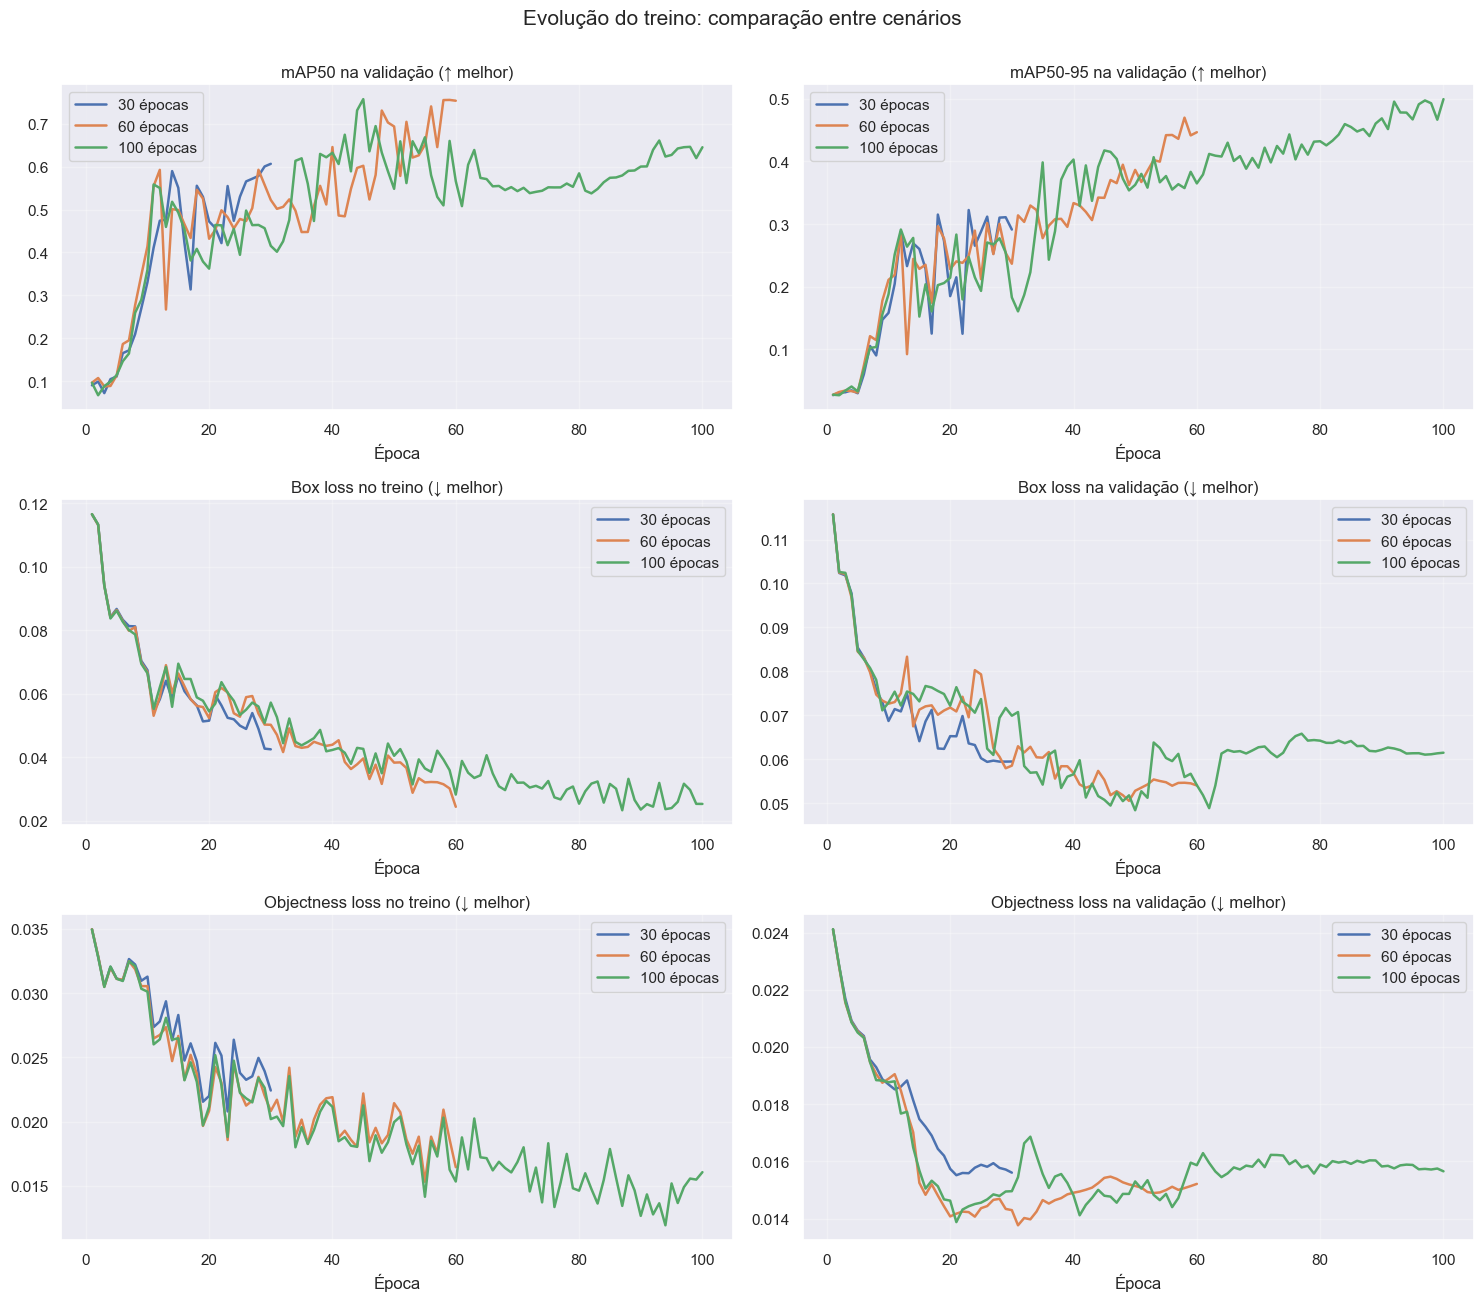

In [ ]:
# ---------------- Curvas de aprendizado por cenário ----------------
import matplotlib.pyplot as plt

# O import do YOLOv5 troca o backend do matplotlib para 'Agg'; a linha abaixo reativa a exibição dos gráficos
%matplotlib inline

graficos = [
    ("metrics/mAP_0.5",      "mAP50 na validação (↑ melhor)"),
    ("metrics/mAP_0.5:0.95", "mAP50-95 na validação (↑ melhor)"),
    ("train/box_loss",       "Box loss no treino (↓ melhor)"),
    ("val/box_loss",         "Box loss na validação (↓ melhor)"),
    ("train/obj_loss",       "Objectness loss no treino (↓ melhor)"),
    ("val/obj_loss",         "Objectness loss na validação (↓ melhor)"),
]

fig, axes = plt.subplots(3, 2, figsize=(15, 13))
for ax, (coluna, titulo) in zip(axes.flat, graficos):
    for ep in EPOCAS:
        hist = ler_resultados(ep)
        ax.plot(hist["epoch"] + 1, hist[coluna], label=f"{ep} épocas", linewidth=1.8)
    ax.set_title(titulo)
    ax.set_xlabel("Época")
    ax.grid(alpha=0.3)
    ax.legend()

plt.suptitle("Evolução do treino: comparação entre cenários", fontsize=15, y=1.0)
plt.tight_layout()
plt.savefig(f"{RESULT_DIR}/curvas_comparativas.png", dpi=120, bbox_inches="tight")
plt.show()

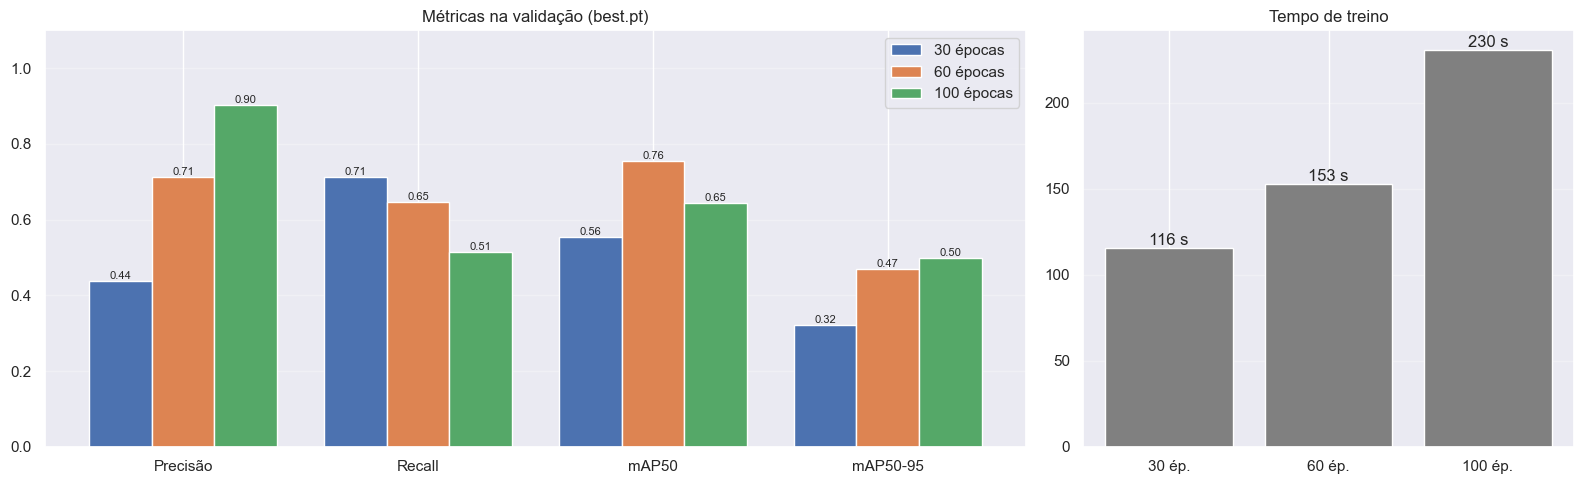

In [ ]:
# ---------------- Comparação visual das métricas finais ----------------
import numpy as np

metricas = ["Precisão", "Recall", "mAP50", "mAP50-95"]
x = np.arange(len(metricas))                                     # posição de cada grupo de barras
largura = 0.8 / len(EPOCAS)                                      # largura de cada barra

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [2, 1]})

for i, ep in enumerate(EPOCAS):                                  # uma barra por cenário em cada métrica
    valores = comparativo.loc[ep, metricas].values
    barras = ax1.bar(x + i * largura, valores, largura, label=f"{ep} épocas")
    ax1.bar_label(barras, fmt="%.2f", fontsize=8)
ax1.set_xticks(x + largura * (len(EPOCAS) - 1) / 2)
ax1.set_xticklabels(metricas)
ax1.set_ylim(0, 1.1)
ax1.set_title("Métricas na validação (best.pt)")
ax1.legend()
ax1.grid(axis="y", alpha=0.3)

barras = ax2.bar([f"{ep} ép." for ep in EPOCAS], comparativo["Tempo treino (s)"], color="gray")
ax2.bar_label(barras, fmt="%.0f s")
ax2.set_title("Tempo de treino")
ax2.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(f"{RESULT_DIR}/metricas_comparativas.png", dpi=120, bbox_inches="tight")
plt.show()

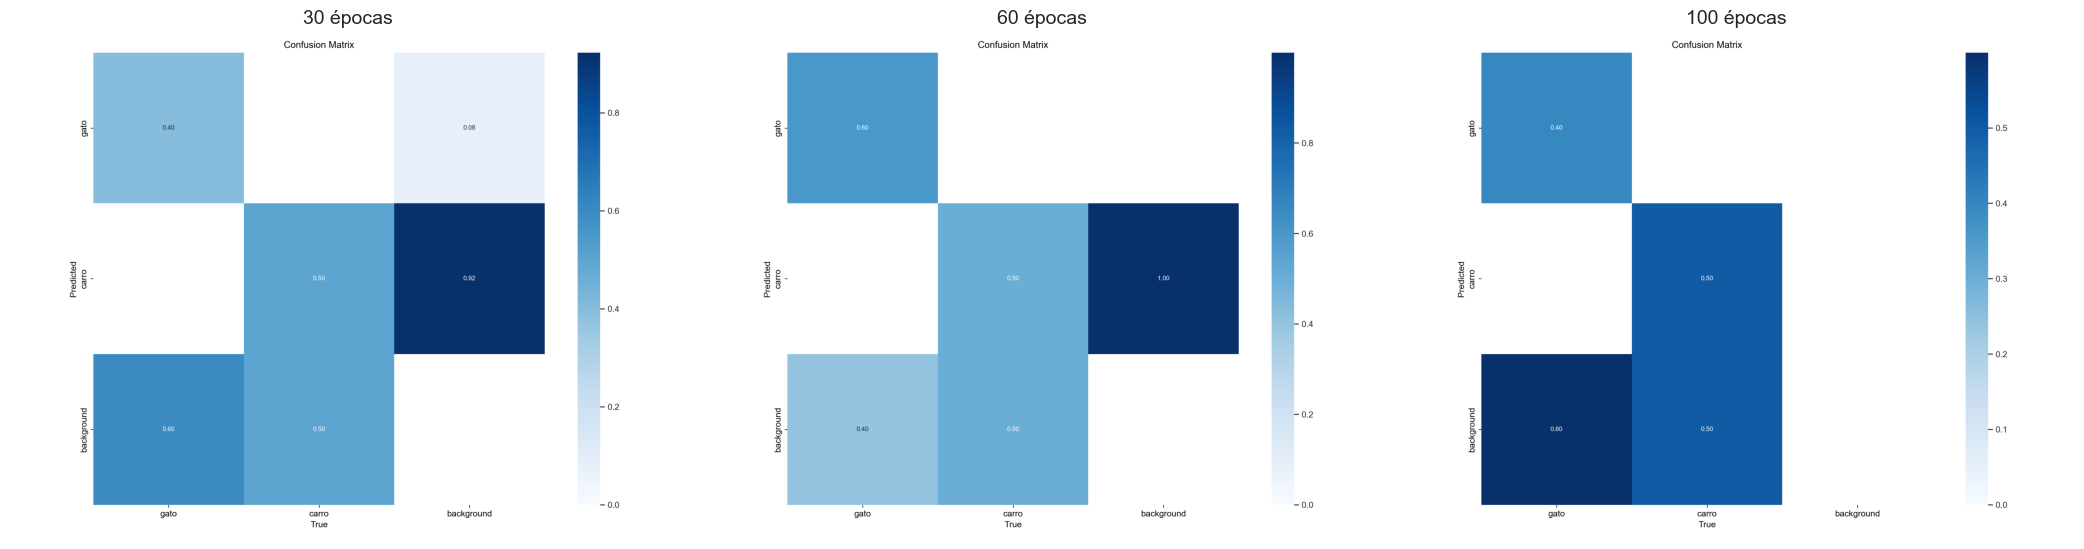

In [ ]:
# ---------------- Matrizes de confusão de cada cenário ----------------
fig, axes = plt.subplots(1, len(EPOCAS), figsize=(7 * len(EPOCAS), 6), squeeze=False)

for ax, ep in zip(axes[0], EPOCAS):
    ax.imshow(plt.imread(f"{YOLO_DIR}/runs/train/treino_{ep}ep/confusion_matrix.png"))
    ax.set_title(f"{ep} épocas", fontsize=14)
    ax.axis("off")

plt.tight_layout()
plt.show()

### Como ler os resultados da validação

- **Curvas de mAP:** mostram em que época o modelo para de evoluir. Se as curvas de 60 e 100 épocas estabilizam no mesmo patamar, épocas extras só custam tempo.
- **Box loss treino x validação:** se a perda de treino continua caindo enquanto a de validação estabiliza ou sobe, é sinal de **overfitting**.
- **Coluna "Melhor época":** se o `best.pt` do cenário de 100 épocas veio de uma época bem anterior à final, as últimas épocas não agregaram.
- **Matriz de confusão:** a linha/coluna `background` mostra objetos não detectados (falsos negativos) e detecções em áreas vazias (falsos positivos). Confusão direta entre gato e carro deve ser rara, já que as classes são visualmente muito diferentes.

> ⚠️ **Atenção à escala da validação:** com apenas 13 objetos, um único acerto ou erro muda o recall em ~8 pontos percentuais. Diferenças pequenas entre cenários não são estatisticamente conclusivas.

## 8. Teste: inferência em imagens nunca vistas

As 9 imagens de teste (4 gatos, 4 carros e 1 mista) **não participaram do treino nem da escolha do best.pt**. Elas simulam o uso real do sistema pelo cliente.

Rodamos o `detect.py` com o `best.pt` de cada cenário (confiança mínima de 25%). Os resultados ficam em `yolov5/runs/detect/teste_XXep` (equivalente às pastas `expX` citadas no enunciado, mas com nomes descritivos).

Como o teste não foi rotulado, fazemos uma **avaliação em nível de imagem**: a detecção é considerada correta quando as classes detectadas coincidem exatamente com as esperadas pelo grupo de origem (ex.: uma imagem de gato deve conter apenas detecções de gato).

In [ ]:
# ---------------- Inferência nas imagens de teste ----------------
%cd {YOLO_DIR}
tempos_teste = {}

for ep in EPOCAS:
    print(f"\n----- Teste: {ep} épocas -----")
    inicio = time.perf_counter()
    !python detect.py --weights runs/train/treino_{ep}ep/weights/best.pt --source {DATASET_DIR}/images/test --img {IMG_SIZE} --conf-thres {CONF_TESTE} --save-txt --save-conf --name teste_{ep}ep --exist-ok
    tempos_teste[ep] = round(time.perf_counter() - inicio, 1)    # inclui carregar o modelo

    shutil.copytree(f"{YOLO_DIR}/runs/detect/teste_{ep}ep", f"{RESULT_DIR}/teste_{ep}ep", dirs_exist_ok=True)

print("\nTempo total do detect.py por cenário (s):", tempos_teste)

/content/yolov5

----- Teste: 30 épocas -----
detect: weights=['runs/train/treino_30ep/weights/best.pt'], source=/content/dataset/images/test, data=data/coco128.yaml, imgsz=[640, 640], conf_thres=0.25, iou_thres=0.45, max_det=1000, device=, view_img=False, save_txt=True, save_format=0, save_csv=False, save_conf=True, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=False, update=False, project=runs/detect, name=teste_30ep, exist_ok=True, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
image 1/9 /content/dataset/images/test/000000010363.jpg: 384x640 1 gato, 1 carro, 61.0ms
image 2/9 /content/dataset/images/test/000000080949.jpg: 448x640 1 gato, 36.7ms
image 3/9 /content/dataset/images/test/000000187236.jpg: 480x640 2 gatos, 33.5ms
image 4/9 /c

In [ ]:
# ---------------- Avaliação em nível de imagem no teste ----------------
manif = pd.read_csv(os.path.join(BASE_DIR, "manifesto_dataset.csv"))
teste = manif[manif.divisao == "teste"].sort_values(["grupo", "arquivo"])
ESPERADO_NOMES = {"gato": {"gato"}, "carro": {"carro"}, "mista": {"gato", "carro"}}

registros = []
for ep in EPOCAS:
    pasta = f"{YOLO_DIR}/runs/detect/teste_{ep}ep/labels"
    for _, r in teste.iterrows():
        arq = os.path.join(pasta, os.path.splitext(r.arquivo)[0] + ".txt")
        dets = []
        if os.path.exists(arq):                                  # sem arquivo = nenhuma detecção
            with open(arq) as f:
                dets = [l.split() for l in f if l.strip()]
        detectadas = {CLASSES[int(d[0])] for d in dets}           # classes encontradas na imagem
        registros.append({
            "Épocas": ep,
            "Arquivo": r.arquivo,
            "Grupo": r.grupo,
            "Detectado": ", ".join(sorted(detectadas)) or "nada",
            "Nº detecções": len(dets),
            "Confiança média": round(np.mean([float(d[5]) for d in dets]), 2) if dets else None,
            "Acerto": detectadas == ESPERADO_NOMES[r.grupo],
        })

df_teste = pd.DataFrame(registros)

# Resumo por cenário: acurácia em nível de imagem e confiança média
resumo_teste = df_teste.groupby("Épocas").agg(
    Acertos=("Acerto", "sum"),
    Total=("Acerto", "size"),
    Confiança_média=("Confiança média", "mean"),
)
resumo_teste["Acurácia (imagem)"] = (resumo_teste.Acertos / resumo_teste.Total).round(3)
resumo_teste["Tempo detect.py (s)"] = pd.Series(tempos_teste)
resumo_teste = resumo_teste.round(3)

resumo_teste.to_csv(f"{RESULT_DIR}/resumo_teste.csv")
df_teste.to_csv(f"{RESULT_DIR}/detalhe_teste.csv", index=False)

display(resumo_teste)
display(df_teste.pivot(index=["Arquivo", "Grupo"], columns="Épocas", values="Detectado"))

,Acertos,Total,Confiança_média,Acurácia (imagem),Tempo detect.py (s)
Épocas,,,,,
30,9,9,0.453,1.000,8.5
60,8,9,0.698,0.889,7.7
100,9,9,0.701,1.000,6.8


,Épocas,30,60,100
Arquivo,Grupo,,,
000000010363.jpg,mista,"carro, gato","carro, gato","carro, gato"
000000080949.jpg,gato,gato,gato,gato
000000187236.jpg,gato,gato,nada,gato
000000230008.jpg,carro,carro,carro,carro
000000261982.jpg,carro,carro,carro,carro
000000394510.jpg,carro,carro,carro,carro
000000425390.jpg,gato,gato,gato,gato
000000443303.jpg,gato,gato,gato,gato
000000555050.jpg,carro,carro,carro,carro


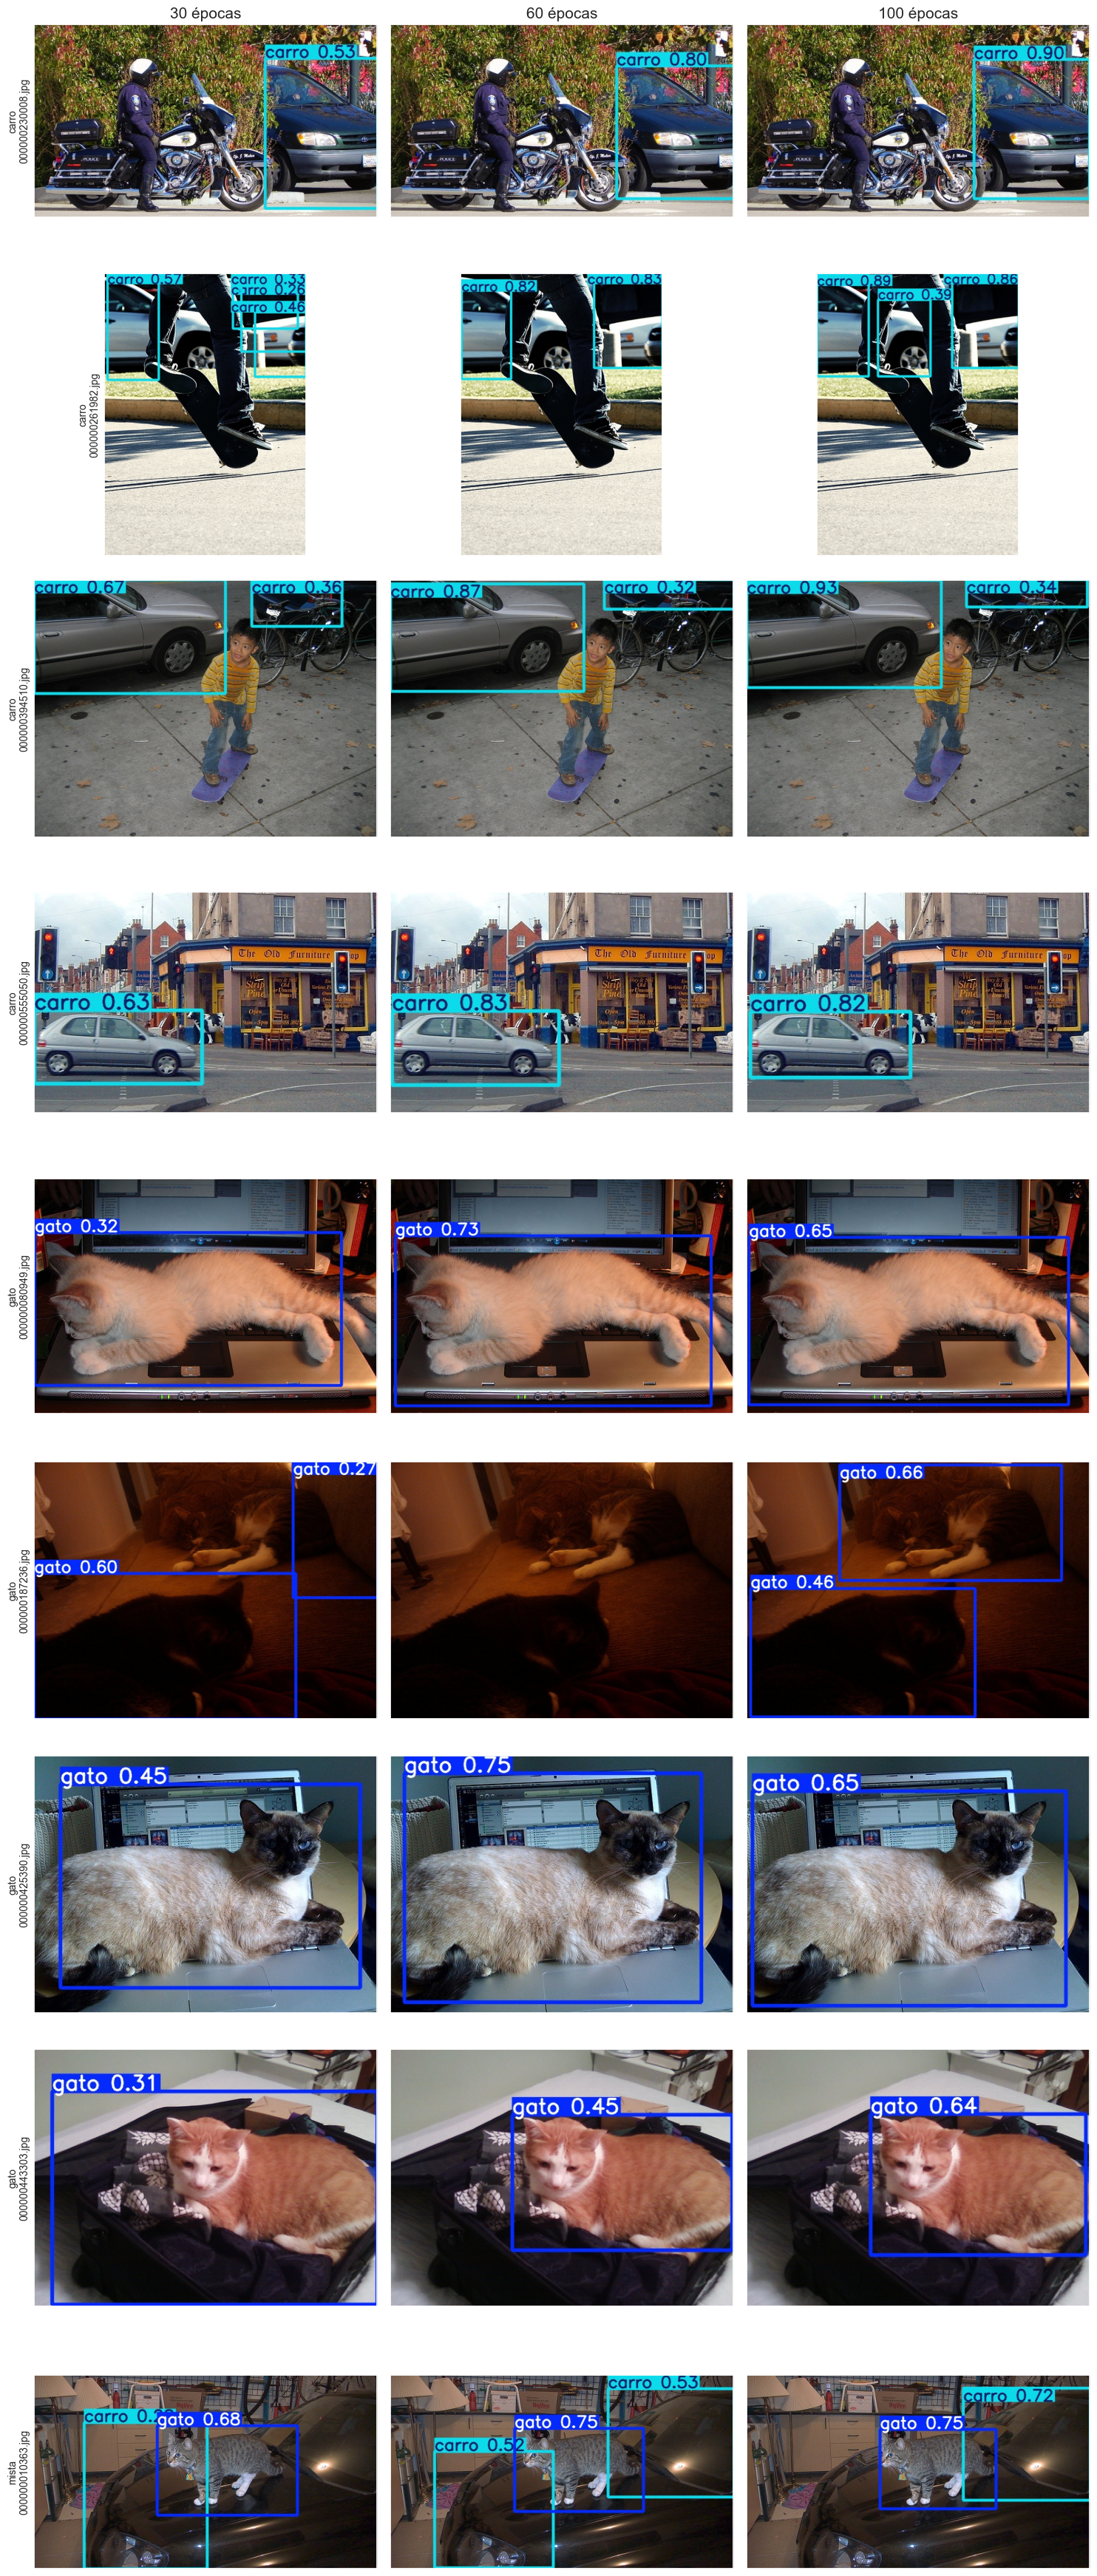

In [ ]:
# ---------------- Prints do teste: mesma imagem em cada cenário ----------------
grupos = dict(zip(manif.arquivo, manif.grupo))                     # arquivo -> grupo de origem
imgs_teste = list(teste.arquivo)

fig, axes = plt.subplots(len(imgs_teste), len(EPOCAS),
                         figsize=(5 * len(EPOCAS), 4 * len(imgs_teste)), squeeze=False)

for i, nome in enumerate(imgs_teste):
    for j, ep in enumerate(EPOCAS):
        ax = axes[i, j]
        ax.imshow(plt.imread(f"{YOLO_DIR}/runs/detect/teste_{ep}ep/{nome}"))   # imagem com as caixas
        ax.set_xticks([]); ax.set_yticks([])
        if i == 0:
            ax.set_title(f"{ep} épocas", fontsize=15, fontweight="bold")
        if j == 0:
            ax.set_ylabel(f"{grupos[nome]}\n{nome}", fontsize=10)

plt.tight_layout()
plt.savefig(f"{RESULT_DIR}/teste_comparativo.png", dpi=100, bbox_inches="tight")
plt.show()

Cenário recomendado: 60 épocas


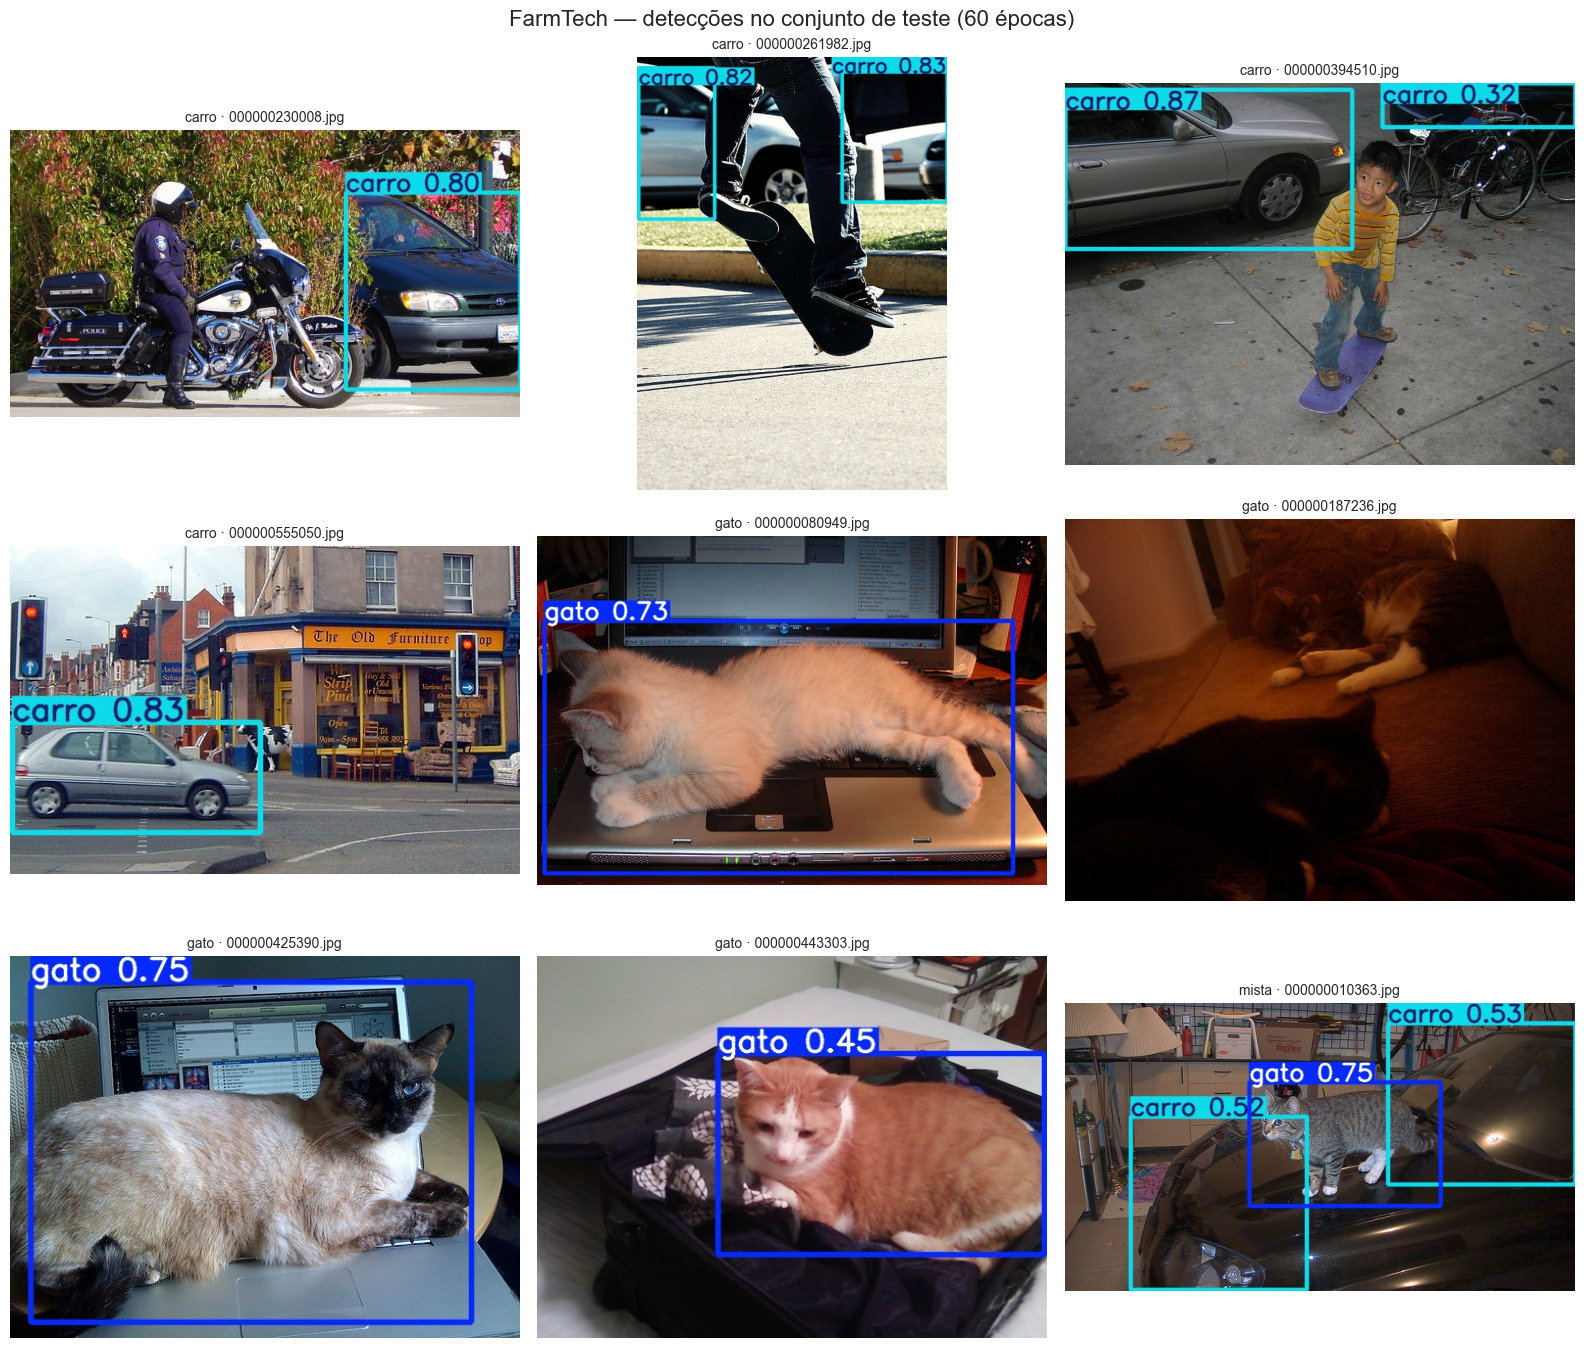

In [ ]:
# ---------------- Prints em destaque: melhor cenário (para apresentar ao cliente) ----------------
melhor_ep = 60   # cenário recomendado nas conclusões (melhor mAP50, recall e acerto de 9/9 no teste)
print(f"Cenário recomendado: {melhor_ep} épocas")

fig, axes = plt.subplots(3, 3, figsize=(16, 14))
for ax, nome in zip(axes.flat, imgs_teste):
    ax.imshow(plt.imread(f"{YOLO_DIR}/runs/detect/teste_{melhor_ep}ep/{nome}"))
    ax.set_title(f"{grupos[nome]} · {nome}", fontsize=10)
    ax.axis("off")

plt.suptitle(f"FarmTech — detecções no conjunto de teste ({melhor_ep} épocas)", fontsize=16)
plt.tight_layout()
plt.savefig(f"{RESULT_DIR}/teste_melhor_cenario.png", dpi=120, bbox_inches="tight")
plt.show()

## 9. Conclusões

### Comparação entre os cenários de épocas

| Aspecto | 30 épocas | 60 épocas | 100 épocas |
|---|---|---|---|
| mAP50 (validação) | 0,555 | **0,755** | 0,645 |
| mAP50-95 (validação) | 0,322 | 0,470 | **0,500** |
| Precisão / Recall | 0,437 / **0,712** | 0,712 / 0,647 | **0,903** / 0,514 |
| mAP50-95 gato / carro | 0,332 / 0,313 | 0,499 / **0,441** | **0,577** / 0,423 |
| Melhor época (best.pt) | 23 | 58 | 100 |
| Acurácia em imagem (teste) | **9/9** | 8/9 | **9/9** |
| Confiança média (teste) | 0,45 | 0,70 | 0,70 |
| Tempo de treino | 116 s | 153 s | 231 s |
| Inferência (ms/img) | 35,3* | 4,6 | 6,5 |

\* Valor inflado pelo aquecimento da GPU na primeira validação executada (inicialização dos kernels CUDA). Como a arquitetura é a mesma nos três cenários, o tempo real é equivalente ao dos demais (~4 a 6 ms; a diferença entre 4,6 e 6,5 ms é oscilação normal de medição).

**Acurácia:** com 30 épocas o modelo ficou **subtreinado**. Ele encontrava a maioria dos objetos (recall 0,712), mas com baixa precisão (0,437): gerava muitos falsos positivos, sobretudo de carro, como mostram a matriz de confusão (coluna `background`) e a imagem `000000261982.jpg`, com várias caixas sobrepostas. De 30 para 60 épocas houve o maior ganho: mAP50 de 0,555 para 0,755 e precisão de 0,437 para 0,712, com recall ainda alto (0,647).

De 60 para 100 épocas o comportamento mudou de natureza. O mAP50-95 subiu (0,470 → 0,500) e a precisão chegou a 0,903, ou seja, caixas mais bem ajustadas e menos alarmes falsos (a matriz de confusão de 100 épocas não tem falsos positivos de fundo). Em contrapartida, o mAP50 caiu para 0,645 e o recall para 0,514: o modelo ficou **mais conservador**, deixando de detectar parte dos objetos. As curvas mostram que o mAP50 do cenário de 100 épocas atingiu o pico perto da época 45 e depois recuou, enquanto o mAP50-95 seguiu crescendo lentamente.

Por classe, o **gato** melhorou continuamente com mais épocas (mAP50-95 de 0,332 para 0,577), enquanto o **carro** teve o melhor resultado em 60 épocas (0,441). Carros são a classe mais difícil: aparecem em maior número por imagem, em tamanhos menores, parcialmente cobertos e com grande variedade visual.

**Erro:** a box loss de treino caiu continuamente nos três cenários, mas a de validação parou de cair perto da época 50 e voltou a subir no cenário de 100 épocas (valor final de 0,0615, contra 0,0540 com 60 épocas). A objectness loss de validação mostra o mesmo padrão a partir da época ~40. Esse descolamento entre treino e validação é um sinal de **início de overfitting**: o modelo continua melhorando no treino sem ganho equivalente em dados novos.

**Teste:** os três cenários acertaram a imagem mista, detectando gato e carro na mesma cena. O de 60 épocas não detectou os dois gatos da imagem `000000187236.jpg`, uma cena com **pouca luz** e animais de pelagem escura. O de 30 épocas acertou 9/9 no critério por imagem, mas com confiança média baixa (0,45) e caixas imprecisas, por exemplo, uma caixa de gato cobrindo uma região sem gato nessa mesma imagem. Isso mostra que a acurácia em nível de imagem é um critério **tolerante**: ela não mede a qualidade das caixas. O de 100 épocas acertou 9/9 com as caixas mais justas e a maior confiança (0,70).

**Desempenho:** o tempo de treino cresceu com as épocas (116 s → 153 s → 231 s), enquanto o **tempo de inferência permaneceu na faixa de 4 a 6 ms por imagem**, já que a arquitetura (YOLOv5s) é a mesma. Treinar mais encarece apenas o desenvolvimento, não o uso em produção.

**Variabilidade entre execuções:** este notebook foi executado duas vezes com a mesma semente. Mesmo assim, as métricas variaram, porque o treino em GPU não é totalmente determinístico. Na execução anterior, por exemplo, foi o cenário de 100 épocas que errou uma imagem do teste e o de 60 que acertou 9/9. O que se repetiu nas duas execuções foi: 30 épocas subtreinado; 60 épocas com o melhor mAP50; 100 épocas com maior precisão, melhor mAP50-95 e menor recall. Essas são as conclusões mais confiáveis do experimento.

**Cenário recomendado: 60 épocas.** Ele teve o melhor mAP50 e o melhor resultado para carros nas duas execuções, equilíbrio entre precisão (0,712) e recall (0,647) e cerca de 2/3 do tempo de treino do cenário de 100 épocas. Para as aplicações da FarmTech (monitoramento animal e segurança patrimonial), **deixar de detectar um objeto costuma ser mais grave que um alarme falso**, o que favorece o cenário com recall maior. O cenário de 100 épocas é a melhor escolha se o cliente priorizar caixas precisas e poucos alarmes falsos. O erro de 60 épocas na imagem com pouca luz indica que esse tipo de cena deve ser reforçado no dataset antes do uso real.

> ⚠️ Com apenas 13 objetos na validação e 9 imagens no teste, uma única detecção muda o recall em ~8 pontos percentuais e a acurácia de teste em ~11 pontos. As tendências acima são consistentes com as curvas de perda e se repetiram entre execuções, mas diferenças pontuais entre cenários não são estatisticamente conclusivas.

### Pontos fortes

- **Transfer learning eficiente:** com apenas 67 imagens de treino e poucos minutos de GPU, o modelo aprendeu a localizar e diferenciar as duas classes, inclusive na mesma cena.
- **Dataset variado e sem vazamento:** imagens reais do COCO `val2017`, com fundos, ângulos e iluminação diversos, que não foram usadas no pré-treino do YOLOv5.
- **Controle de qualidade dos rótulos:** a verificação semântica identificou e corrigiu um erro de rotulação antes do treino.
- **Experimento controlado e reproduzível:** semente fixa, um único hiperparâmetro variando entre os cenários e rótulos versionados no GitHub.
- **Inferência em tempo real:** poucos milissegundos por imagem na GPU, viável para monitoramento por câmeras.

### Limitações

- **Validação e teste muito pequenos** (9 imagens cada): as métricas oscilam muito com um único erro e variaram entre execuções.
- **Teste sem rótulos de caixa:** a avaliação no teste é feita em nível de imagem (classes presentes) e não mede a qualidade das caixas, como mostrou o cenário de 30 épocas.
- **Sensibilidade a baixa luminosidade:** a cena escura com gatos de pelagem escura foi o caso mais difícil do teste.
- **Poucas imagens mistas** (5 no total), o que limita a avaliação em cenas com os dois objetos.
- **Viés do pré-treino:** gato e carro já são classes do COCO, então parte do bom desempenho vem do conhecimento prévio do modelo. Classes inéditas (ex.: doenças específicas em animais) exigiriam mais dados.
- **Rotulação manual sujeita a erro humano**, como mostrou a correção da Seção 4.
- **Medição de inferência sensível ao aquecimento da GPU:** a primeira avaliação registrou tempo inflado; medições confiáveis exigem uma inferência de aquecimento antes.

### Próximos passos

- Ampliar o dataset, especialmente validação, teste e cenas com pouca luz, para métricas mais estáveis.
- Rotular o teste para calcular mAP também nesse conjunto.
- Repetir cada cenário com várias sementes e reportar média e desvio padrão.
- Testar *early stopping* (`--patience`) e *data augmentation* de brilho e contraste.
- Comparar com modelos maiores (YOLOv5m/l) e com outras abordagens (YOLO padrão e CNN do zero, previstas na Entrega 2).

## 10. Referências

- Lin, T.-Y. et al. **Microsoft COCO: Common Objects in Context**. ECCV, 2014. Dataset: <https://cocodataset.org> (anotações sob licença CC BY 4.0; imagens do Flickr com licenças individuais, registradas no `manifesto_dataset.csv`).
- Ultralytics. **YOLOv5**. <https://github.com/ultralytics/yolov5>
- **Make Sense AI** — ferramenta de rotulação: <https://www.makesense.ai>